In [84]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix,accuracy_score,
recall_score,f1_score,roc_auc_score,precision_score)

df=pd.read_csv(r'C:\Users\USER\Desktop\5thsem_OJT\project1_diabeties\data\prosessed\fizan_P1W2_features.csv')

feature_cols = ["age","pregnancies","glucose","blood_pressure","skin_thickness","insulin","bmi","diabetes_pedigree","bmi_catogory","glucose_band"]
x= pd.get_dummies(df[feature_cols],drop_first=True)
y=df["outcome"]

x_train,x_test,y_train,y_test= train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)
scaler = StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

logreg = LogisticRegression(max_iter=1000).fit(x_train_scaled,y_train)
knn = KNeighborsClassifier(n_neighbors=25).fit(x_train_scaled, y_train)
decision_tree = DecisionTreeClassifier(max_depth=3,random_state=42).fit(x_train, y_train)

def score_row(name, pred, scores=None):
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()

    r = {
        'model' : name,
        'accuracy' : round(accuracy_score(y_test, pred),4),
        'precision' : round(precision_score(y_test, pred, zero_division=0),4),
        'recall' : round(recall_score(y_test, pred, zero_division=0),4),
        'f1' : round(f1_score(y_test,pred,zero_division=0),4),
        'found' : int(tp), 'missed' : int(fn), 'false_alarms' : int(fp)
    }

    if scores is not None :
        r['auc'] = roc_auc_score(y_test, scores)
    return r


print('train:', x_train.shape, 'test:', x_test.shape)
print('Diabetic patients in the test set:', int(np.sum(y_test)),'of', len(y_test))
for nm, m, Xt in [('Logistic Regression', logreg, x_test_scaled),('Decision Tree (d=3)', decision_tree, x_test),('KNN (k=25)', knn, x_test_scaled)]:
    print(f' {nm:22s} accuracy {accuracy_score(y_test, m.predict(Xt)):.4f}')


train: (760, 13) test: (190, 13)
Diabetic patients in the test set: 55 of 190
 Logistic Regression    accuracy 0.7526
 Decision Tree (d=3)    accuracy 0.7211
 KNN (k=25)             accuracy 0.7474


In [120]:
df.columns

Index(['patient_id', 'age', 'gender', 'pregnancies', 'glucose',
       'blood_pressure', 'skin_thickness', 'insulin', 'bmi',
       'diabetes_pedigree', 'physical_activity', 'smoker', 'last_checkup_date',
       'outcome', 'age_band', 'bmi_catogory', 'glucose_band',
       'insulin_glucose_ratio', 'pregnancies_rate', 'since_checkup',
       'activity_smoker'],
      dtype='str')

## restate the target you are aiming at 

In [85]:
TARGET_RECALL = 0.70
GAURD_F1 = 0.50
BEST_SO_FAR = 0.6182 # week 5 logistic regression at threshold 0.30

print('PROJECT METRIC : recall (guard: F1 >=',GAURD_F1,')')
print("TARGET          : recall >=", TARGET_RECALL)
print("BEST SO FAR     :", BEST_SO_FAR, "(Week 5 baseline at threshold 0.30)")
print("GAP TO CLOSE    :", round(TARGET_RECALL - BEST_SO_FAR, 4))

PROJECT METRIC : recall (guard: F1 >= 0.5 )
TARGET          : recall >= 0.7
BEST SO FAR     : 0.6182 (Week 5 baseline at threshold 0.30)
GAP TO CLOSE    : 0.0818


How an SVM Makes a Decision
An SVM (Support Vector Machine) classifies data by finding a boundary between groups.
Hyperplane: The boundary that separates the groups. In a 2D graph, it is a line; in higher dimensions, it is called a hyperplane.
Support vectors: The data points closest to the hyperplane. They help determine where the boundary is placed.
Margin: The distance between the hyperplane and the nearest support vectors. The SVM tries to make this margin as wide as possible.
Decision process
The SVM finds a hyperplane that separates the groups.
It uses the support vectors to position the hyperplane.
It chooses a hyperplane with a wide margin.
For a new data point, it checks which side of the hyperplane the point falls on and predicts that group.

## Train an SVM with default settings 

In [86]:
from sklearn.svm import SVC # rbf is used for non linear , it is a kernal

svm_rbf = SVC(random_state=42)
svm_rbf.fit(x_train_scaled, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


predict from the new model

In [87]:
pred_rbf = svm_rbf.predict(x_test_scaled)
print('fitted :',svm_rbf)
print('patients flagged :', int(pred_rbf.sum()), 'of', len(pred_rbf))

fitted : SVC(random_state=42)
patients flagged : 19 of 190


In [88]:
row_rbf = score_row('SVC rbf ', pred_rbf,svm_rbf.decision_function(x_test_scaled))
print(pd.DataFrame([row_rbf]).to_string(index=False))
print()
print('Target recall:', TARGET_RECALL,'| Best so far:', BEST_SO_FAR)
print('This model :', row_rbf['recall'])

   model  accuracy  precision  recall     f1  found  missed  false_alarms      auc
SVC rbf     0.7368     0.6316  0.2182 0.3243     12      43             7 0.637845

Target recall: 0.7 | Best so far: 0.6182
This model : 0.2182


## Try a straight boundary instead

In [89]:
svm_linear = SVC(kernel='linear', random_state=42)
svm_linear.fit(x_train_scaled, y_train)
pred_linear = svm_linear.predict(x_test_scaled)
print('fitted :' ,svm_linear)
print()
print('patients flagged :', int(pred_linear.sum()), 'of', len(pred_linear))



fitted : SVC(kernel='linear', random_state=42)

patients flagged : 0 of 190


In [90]:
row_linear = score_row('SVC linear', pred_linear,svm_linear.decision_function(x_test_scaled))
print(pd.DataFrame([row_linear,row_rbf]).to_string(index=False))

     model  accuracy  precision  recall     f1  found  missed  false_alarms      auc
SVC linear    0.7105     0.0000  0.0000 0.0000      0      55             0 0.688485
  SVC rbf     0.7368     0.6316  0.2182 0.3243     12      43             7 0.637845


## look closely at what the linear SVM predicted 

In [91]:
print("Patient the linear SVM flagged as diabetic:",int(pred_linear.sum()),"of", len(pred_linear))
print()
print("Confusion of linear:",
      confusion_matrix(y_test,pred_linear))
print()

print('Dummy :', confusion_matrix(y_test,np.zeros_like(y_test)))

print("Linear accuracy:", round(accuracy_score(y_test,pred_linear),4))
print('Dummy accuracy:', round(accuracy_score(y_test,np.zeros_like(y_test)),4))

Patient the linear SVM flagged as diabetic: 0 of 190

Confusion of linear: [[135   0]
 [ 55   0]]

Dummy : [[135   0]
 [ 55   0]]
Linear accuracy: 0.7105
Dummy accuracy: 0.7105


## What Class weight 
Ans:- class_weight gives different importance to different classes during model training.
It is mainly used for imbalanced datasets, giving more weight to the minority class.
class_weight="balanced" automatically gives higher importance to the minority class.

In [92]:
svm_rbf_bal = SVC(random_state=42 , class_weight='balanced').fit(x_train_scaled,y_train)
pred_rbf_bal = svm_rbf_bal.predict(x_test_scaled)
svm_linear_bal = SVC(kernel='linear' , random_state=42, class_weight='balanced').fit(x_train_scaled, y_train) 
pred_linear_bal = svm_linear_bal.predict(x_test_scaled)


row_linear_bal = score_row('SVC linear balanced', pred_linear_bal,svm_linear.decision_function(x_test_scaled))
row_rbf_bal = score_row('SVC rbf balanced ', pred_rbf_bal,svm_rbf_bal.decision_function(x_test_scaled))

print(pd.DataFrame([row_linear,row_linear_bal,row_rbf,row_rbf_bal]).to_string(index=False))

              model  accuracy  precision  recall     f1  found  missed  false_alarms      auc
         SVC linear    0.7105     0.0000  0.0000 0.0000      0      55             0 0.688485
SVC linear balanced    0.6579     0.4375  0.6364 0.5185     35      20            45 0.688485
           SVC rbf     0.7368     0.6316  0.2182 0.3243     12      43             7 0.637845
  SVC rbf balanced     0.6421     0.4198  0.6182 0.5000     34      21            47 0.680269


svm_rbf_bal = SVC(random_state=42, class_weight="balanced").fit(
    x_train_scaled, y_train)
svm_lin_bal = SVC(kernel="linear", random_state=42,
                  class_weight="balanced").fit(
    x_train_scaled, y_train)
rows = [
    row_rbf,
    score_row(
        "SVC rbf (balanced)",
        svm_rbf_bal.predict(x_test_scaled),
        svm_rbf_bal.decision_function(x_test_scaled)
    ),
    row_lin,
    score_row(
        "SVC linear (balanced)",
        svm_lin_bal.predict(x_test_scaled),
        svm_lin_bal.decision_function(x_test_scaled)
    )]
svm_table = pd.DataFrame(rows)
print(svm_table.to_string(index=False))

## Get a risk score out of SVM

In [93]:
score_bal = svm_rbf_bal.decision_function(x_test_scaled)
print()
print('decision_function output for the first 8 test patients  ')
print(np.round(score_bal[:8],3))
print()
print('negative = healthy side of the boundary, positive = diabetic side')
print()
print('AUC from decision_function:',
      round(roc_auc_score(y_test, score_bal), 4))
print()
print("AUC of the linear SVM that found nobody:",
      round(roc_auc_score(y_test, svm_linear.decision_function(x_test_scaled)), 4))


decision_function output for the first 8 test patients  
[ 0.167 -1.654 -0.666 -0.648 -0.782 -1.159  0.732  1.104]

negative = healthy side of the boundary, positive = diabetic side

AUC from decision_function: 0.6803

AUC of the linear SVM that found nobody: 0.6885


## check how much of the data the boundary rests on 

In [94]:
print('support vectors per class ', svm_rbf.n_support_)
print('total support:', svm_rbf.n_support_.sum(),'of', len(y_train),
      f'= {svm_rbf.n_support_.sum() / len(y_train)*100:.1f}% of the training set')

support vectors per class  [276 210]
total support: 486 of 760 = 63.9% of the training set


## try one change to c


In [95]:
svm_c10 = SVC(random_state=42, C=10).fit(x_train_scaled,y_train)
print(pd.DataFrame([
    row_rbf, 
    score_row("svm_c10", svm_c10.predict(x_test_scaled), svm_c10.decision_function(x_test_scaled))
]).to_string(index=False))

   model  accuracy  precision  recall     f1  found  missed  false_alarms      auc
SVC rbf     0.7368     0.6316  0.2182 0.3243     12      43             7 0.637845
 svm_c10    0.6789     0.4211  0.2909 0.3441     16      39            22 0.624916


In [96]:
svm_c10 = SVC(random_state=42, C=10).fit(x_train_scaled, y_train)

print(pd.DataFrame([
    row_rbf,
    score_row(
        "SVC rbf C=10",
        svm_c10.predict(x_test_scaled),
        svm_c10.decision_function(x_test_scaled)
    )
]).to_string(index=False))

       model  accuracy  precision  recall     f1  found  missed  false_alarms      auc
    SVC rbf     0.7368     0.6316  0.2182 0.3243     12      43             7 0.637845
SVC rbf C=10    0.6789     0.4211  0.2909 0.3441     16      39            22 0.624916


## Random Forest
Explain why Random tree beat decision tree ?

Ans :- Random Forest is generally better than a Decision Tree because it combines multiple decision trees to make predictions. It reduces overfitting, improves stability, and often provides better accuracy on unseen data. However, it requires more computational resources and is harder to interpret

Reduces overfitting: It combines multiple trees instead of depending on just one.



Improves stability: Predictions are generally less sensitive to small changes in the training data.



Can improve accuracy: Combining different trees often produces better predictions on unseen data.



Handles complex patterns: It can learn different patterns from different samples and features.

Explain what makes tree different from each other ?

Each tree in a Random Forest is different because it uses randomly selected training samples and considers random subsets of features at each split. This creates different tree structures and predictions. Combining their predictions helps reduce overfitting and improve reliability.



Two Sources of Randomness in Random Forest
Random Forest uses two main sources of randomness to make its decision trees different from each other.
1. Bootstrap Sampling (Random Data Samples)
- Each tree is trained on a randomly selected sample of the original training dataset.
- Sampling is done with replacement, meaning the same row can be selected more than once.
- Therefore, different trees learn from different data samples.
Example: If a dataset has 100 patient records, Tree 1 and Tree 2 may receive different sets of 100 sampled records.
2. Random Feature Selection
- At each split, the tree considers only a random subset of the available features.
- It selects the best splitting feature from that subset.
- This helps trees learn different patterns.
Example: Suppose the features are Age, Glucose, BMI, and Blood Pressure. One tree may consider Age and Glucose, while another considers BMI and Blood Pressure at a particular split.





## Train a Random Forest with default settings


In [97]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)
rf.fit(x_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [98]:
row_rf = score_row("random forest",rf.predict(x_test),rf.predict_proba(x_test)[:,1])
print(pd.DataFrame([row_rf]).to_string(index=False))

        model  accuracy  precision  recall     f1  found  missed  false_alarms      auc
random forest    0.7158     0.5185  0.2545 0.3415     14      41            13 0.698047


In [99]:
print("Random Forest (default, 100 trees)")
print("Training accuracy:", round(accuracy_score(y_train, rf.predict(x_train)), 4))
print("Test accuracy    :", round(accuracy_score(y_test, rf.predict(x_test)), 4))

print()

print("Week 4 unrestricted single tree")
print("Training accuracy: 1.0")
print("Test accuracy    : 0.6474")

Random Forest (default, 100 trees)
Training accuracy: 1.0
Test accuracy    : 0.7158

Week 4 unrestricted single tree
Training accuracy: 1.0
Test accuracy    : 0.6474


In [100]:
print("distint probabiIities - random forest :",
    len(np.unique(rf.predict_proba(x_test)[:, 1])))
print("Ditinct probabiIities - week 4 tree :",
    len(np.unique(decision_tree.predict_proba(x_test)[:,1])))

distint probabiIities - random forest : 66
Ditinct probabiIities - week 4 tree : 6


In [101]:
print(f"{'model':28s} {'recall':>8s} {'f1':>8s}")
print(f"{'Random Forest (default)':28s} {row_rf['recall']:8.4f} {row_rf['f1']:8.4f}")
print(f"{'Best so far (W5 tuned)':28s} {BEST_SO_FAR:8.4f} {0.5397:8.4F}")
print(f"{'TARGET':28s} {TARGET_RECALL:8.4f} {GAURD_F1:8.4f}")
print()
print("Closed the gap?", row_rf['recall'] >= TARGET_RECALL)

model                          recall       f1
Random Forest (default)        0.2545   0.3415
Best so far (W5 tuned)         0.6182   0.5397
TARGET                         0.7000   0.5000

Closed the gap? False


## Controlling the Forest

In [102]:
rf_bal = RandomForestClassifier(
    random_state=42,
    class_weight="balanced"
).fit(x_train, y_train)

row_rf_bal = score_row(
    "RF balanced",
    rf_bal.predict(x_test),
    rf_bal.predict_proba(x_test)[:, 1]
)

print(pd.DataFrame([row_rf, row_rf_bal]).to_string(index=False))

        model  accuracy  precision  recall     f1  found  missed  false_alarms      auc
random forest    0.7158     0.5185  0.2545 0.3415     14      41            13 0.698047
  RF balanced    0.7105     0.5000  0.4364 0.4660     24      31            24 0.685387


In [103]:
rf_d5 = RandomForestClassifier(random_state=43, max_depth=5).fit(x_train,y_train)
rf_d5_bal = RandomForestClassifier(random_state=42, max_depth=5,class_weight="balanced").fit(x_train, y_train)

row_rf_d5 = score_row(
    "Random Forest (depth=5)",
    rf_d5.predict(x_test),
    rf_d5.predict_proba(x_test)[:, 1]
)

row_rf_d5_bal = score_row(
    "Random Forest (depth=5, balanced)",
    rf_d5_bal.predict(x_test),
    rf_d5_bal.predict_proba(x_test)[:, 1]
)

print(pd.DataFrame([row_rf_d5, row_rf_d5_bal,row_rf, row_rf_bal]).to_string(index=False))

                            model  accuracy  precision  recall     f1  found  missed  false_alarms      auc
          Random Forest (depth=5)    0.7368     0.7273  0.1455 0.2424      8      47             3 0.722020
Random Forest (depth=5, balanced)    0.6789     0.4625  0.6727 0.5481     37      18            43 0.742357
                    random forest    0.7158     0.5185  0.2545 0.3415     14      41            13 0.698047
                      RF balanced    0.7105     0.5000  0.4364 0.4660     24      31            24 0.685387


In [104]:
variants = [
    ("RF default (100 trees)",
     RandomForestClassifier(random_state=42)),

    ("RF balanced",
     RandomForestClassifier(random_state=42,
                            class_weight="balanced")),

    ("RF max_depth=5",
     RandomForestClassifier(random_state=42, max_depth=5)),

    ("RF max_depth=5 balanced",
     RandomForestClassifier(random_state=42,
                            max_depth=5,
                            class_weight="balanced")),

    ("RF balanced_subsample",
     RandomForestClassifier(random_state=42,
                            class_weight="balanced_subsample"))
]

rows = []

for name, m in variants:
    m.fit(x_train, y_train)

    rows.append(
        score_row(
            name,
            m.predict(x_test),
            m.predict_proba(x_test)[:, 1]
        )
    )

forest_table = pd.DataFrame(rows)

print(forest_table.to_string(index=False))

best = forest_table.sort_values(
    ["recall", "f1"],
    ascending=False
).iloc[0]

print(
    "\nBest on the project metric:",
    best["model"],
    "| recall", best["recall"],
    "| f1", best["f1"]
)

# Keep the winning configuration - used for the rest of the week
rf_best = RandomForestClassifier(
    random_state=42,
    max_depth=5,
    class_weight="balanced"
).fit(x_train, y_train)

                  model  accuracy  precision  recall     f1  found  missed  false_alarms      auc
 RF default (100 trees)    0.7158     0.5185  0.2545 0.3415     14      41            13 0.698047
            RF balanced    0.7105     0.5000  0.4364 0.4660     24      31            24 0.685387
         RF max_depth=5    0.7421     0.7143  0.1818 0.2899     10      45             4 0.736431
RF max_depth=5 balanced    0.6789     0.4625  0.6727 0.5481     37      18            43 0.742357
  RF balanced_subsample    0.7211     0.5455  0.2182 0.3117     12      43            10 0.687542

Best on the project metric: RF max_depth=5 balanced | recall 0.6727 | f1 0.5481


## Try changing the number of trees

In [105]:
import time 
t0 = time.time()
rf_100 = RandomForestClassifier(random_state=42).fit(x_train, y_train)
t_100 = time.time() - t0

t0 = time.time()
rf_300 = RandomForestClassifier(random_state=42, n_estimators=300).fit(x_train, y_train)
t_300 = time.time() - t0

print(pd.DataFrame([score_row("rf_100",rf_100.predict(x_test),rf_100.predict_proba(x_test)[:,1]),
                    score_row("rf_300",rf_300.predict(x_test),rf_300.predict_proba(x_test)[:,1])

]).to_string(index=False))
print()
print(f"Fitting time: 100 trees {t_100: .2f}s | 300 trees {t_300: .2f}s"
      f" ({t_300 / t_100:.1f}x)")

 model  accuracy  precision  recall     f1  found  missed  false_alarms      auc
rf_100    0.7158     0.5185  0.2545 0.3415     14      41            13 0.698047
rf_300    0.7158     0.5172  0.2727 0.3571     15      40            14 0.701886

Fitting time: 100 trees  0.53s | 300 trees  1.71s (3.2x)


## Read the forests feature importence

In [106]:
comparison = pd.DataFrame({
    'forest (default)': pd.Series(rf.feature_importances_, index=x.columns),
    'forest (chosen)': pd.Series(rf_best.feature_importances_, index=x.columns),
    'Week 4 single tree': pd.Series(decision_tree.feature_importances_, index=x.columns)
}).round(4).sort_values('forest (chosen)', ascending=False)

print(comparison.to_string())

                           forest (default)  forest (chosen)  Week 4 single tree
glucose                              0.1771           0.2593              0.5927
age                                  0.1424           0.1399              0.2393
diabetes_pedigree                    0.1272           0.1237              0.0472
bmi                                  0.1237           0.1108              0.0000
glucose_band_diebetic                0.0291           0.0794              0.0000
insulin                              0.1000           0.0786              0.0782
blood_pressure                       0.1124           0.0718              0.0000
skin_thickness                       0.0956           0.0510              0.0426
pregnancies                          0.0503           0.0313              0.0000
bmi_catogory_obeese                  0.0142           0.0238              0.0000
glucose_band_pre_diebetic            0.0124           0.0178              0.0000
bmi_catogory_overweight     

## compare the shape of the two importance rankings 

In [107]:
print('top feature share:')
print('single tree:%.1f%%' % (comparison['Week 4 single tree'].max() * 100))
print('chosen forest :%.1f%%' % (comparison['forest (chosen)'].max() * 100))
print()
print('feature with exactly zero importance:')
print('single tree :', int((comparison['Week 4 single tree']==0).sum()),'of 13')
print('chosen forest :', int((comparison['forest (chosen)']==0).sum()),'of 13')

top feature share:
single tree:59.3%
chosen forest :25.9%

feature with exactly zero importance:
single tree : 8 of 13
chosen forest : 0 of 13


In [108]:
proba_rf = rf_best.predict_proba(x_test)[:,1]
print('Distinct probanilities from this forerst:', len(np.unique(proba_rf)))
print()
sweep = pd.DataFrame([score_row(f'threshold {t:.2f}',(proba_rf >= t).astype(int))
                      for t in [0.60, 0.55, 0.50, 0.45, 0.40, 0.35, 0.30]])
print(sweep.to_string(index=False))

Distinct probanilities from this forerst: 190

         model  accuracy  precision  recall     f1  found  missed  false_alarms
threshold 0.60    0.7474     0.5946  0.4000 0.4783     22      33            15
threshold 0.55    0.7316     0.5370  0.5273 0.5321     29      26            25
threshold 0.50    0.6789     0.4625  0.6727 0.5481     37      18            43
threshold 0.45    0.6263     0.4130  0.6909 0.5170     38      17            54
threshold 0.40    0.6000     0.4037  0.8000 0.5366     44      11            65
threshold 0.35    0.5211     0.3657  0.8909 0.5185     49       6            85
threshold 0.30    0.4421     0.3355  0.9455 0.4952     52       3           103


## find the setting that reaches the target 

In [109]:
hits = sweep[(sweep['recall'] >= TARGET_RECALL) & (sweep['f1'] >= GAURD_F1)]
print('Rows clearing the weekn 5 target (recall >= 0.70 AND F1 >= 0.50):')
print(hits.to_string(index=False) if len (hits) else 'none')
if len(hits):
    b = hits.sort_values('f1',ascending=False).iloc[0]
    print('\nbest of them:',b['model'],'| recall',b['recall'],'| f1', b['f1'], '| found', int(b['found']),'of 55')

Rows clearing the weekn 5 target (recall >= 0.70 AND F1 >= 0.50):
         model  accuracy  precision  recall     f1  found  missed  false_alarms
threshold 0.40    0.6000     0.4037  0.8000 0.5366     44      11            65
threshold 0.35    0.5211     0.3657  0.8909 0.5185     49       6            85

best of them: threshold 0.40 | recall 0.8 | f1 0.5366 | found 44 of 55


## Decide which forest goes into the comparison 

Answer. RandomForestClassifier(max_depth=5, class_wweight='balanced')at the default 0.50 threshold.

it is the best row in the variant table on both the project metric (recall 0.65450) and the guard (f1 0.5455),and unlike the 0.45 threshold candidate it has not been tuned against the test set. the honest week 6 figure is the one that goes forward 

In [110]:
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)
print("Test patients:", len(y_test))
print("Diabetic patients:", int(y_test.sum()))

Training data: (760, 13)
Testing data: (190, 13)
Test patients: 190
Diabetic patients: 55


In [111]:
# T31 — Score the five main models using the Week 5 score_row() function.
# This notebook defines score_row(), not evaluate_model().

models = [
    ("Logistic Regression", logreg, x_test_scaled),
    ("Decision Tree", decision_tree, x_test),
    ("KNN", knn, x_test_scaled),
    ("SVM (balanced RBF)", svm_rbf_bal, x_test_scaled),
    ("Random Forest (chosen)", rf_best, x_test)
]

week6_t31_rows = []

for name, model, Xt in models:
    pred = model.predict(Xt)

    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(Xt)[:, 1]
    else:
        scores = model.decision_function(Xt)

    week6_t31_rows.append(score_row(name, pred, scores))

print(pd.DataFrame(week6_t31_rows).to_string(index=False))


                 model  accuracy  precision  recall     f1  found  missed  false_alarms      auc
   Logistic Regression    0.7526     0.6667  0.2909 0.4051     16      39             8 0.717576
         Decision Tree    0.7211     0.5333  0.2909 0.3765     16      39            14 0.680741
                   KNN    0.7474     0.7333  0.2000 0.3143     11      44             4 0.683704
    SVM (balanced RBF)    0.6421     0.4198  0.6182 0.5000     34      21            47 0.680269
Random Forest (chosen)    0.6789     0.4625  0.6727 0.5481     37      18            43 0.742357


## Week 6 — Block C: Comparison and the Metric Test

Use the same train/test split already created above. These cells use the real fitted models and results from this notebook.

### T32 — Build the full comparison table

This table includes models already trained earlier in the notebook, the Week 5 Logistic Regression threshold of 0.30, and a dummy baseline. It includes all four confusion-matrix counts.

In [112]:
from sklearn.dummy import DummyClassifier

# Fit a simple majority-class baseline using the training data only.
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(x_train, y_train)

# Model, test features, and optional custom prediction threshold.
week6_model_specs = [
    ("Logistic Regression (default)", logreg, x_test_scaled, None),
    ("Decision Tree (depth=3)", decision_tree, x_test, None),
    ("KNN (k=25)", knn, x_test_scaled, None),
    ("SVM RBF (default)", svm_rbf, x_test_scaled, None),
    ("SVM linear (default)", svm_linear, x_test_scaled, None),
    ("SVM RBF (balanced)", svm_rbf_bal, x_test_scaled, None),
    ("SVM linear (balanced)", svm_linear_bal, x_test_scaled, None),
    ("SVM RBF (C=10)", svm_c10, x_test_scaled, None),
    ("Random Forest (default)", rf, x_test, None),
    ("Random Forest (balanced)", rf_bal, x_test, None),
    ("Random Forest (depth=5)", rf_d5, x_test, None),
    ("Random Forest (depth=5, balanced)", rf_d5_bal, x_test, None),
    ("Random Forest (chosen)", rf_best, x_test, None),
    ("Random Forest (300 trees)", rf_300, x_test, None),
    ("Dummy baseline", dummy_model, x_test, None),
]

# Week 5 threshold-tuned Logistic Regression is scored separately.
week6_results_rows = []

def week6_add_result(name, y_pred, scores):
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
    week6_results_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "auc": roc_auc_score(y_test, scores),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "found": int(tp), "missed": int(fn), "false_alarms": int(fp)
    })

for name, model, Xt, threshold in week6_model_specs:
    y_pred = model.predict(Xt)
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(Xt)[:, 1]
    else:
        scores = model.decision_function(Xt)
    if threshold is not None:
        y_pred = (scores >= threshold).astype(int)
    week6_add_result(name, y_pred, scores)

# Week 5 baseline: Logistic Regression probabilities with threshold 0.30.
logreg_probs = logreg.predict_proba(x_test_scaled)[:, 1]
logreg_tuned_pred = (logreg_probs >= 0.30).astype(int)
week6_add_result("Logistic Regression (threshold=0.30)",
                 logreg_tuned_pred, logreg_probs)

results = pd.DataFrame(week6_results_rows)
print(results.round(4).to_string(index=False))


                               model  accuracy  precision  recall     f1    auc  TN  FP  FN  TP  found  missed  false_alarms
       Logistic Regression (default)    0.7526     0.6667  0.2909 0.4051 0.7176 127   8  39  16     16      39             8
             Decision Tree (depth=3)    0.7211     0.5333  0.2909 0.3765 0.6807 121  14  39  16     16      39            14
                          KNN (k=25)    0.7474     0.7333  0.2000 0.3143 0.6837 131   4  44  11     11      44             4
                   SVM RBF (default)    0.7368     0.6316  0.2182 0.3243 0.6378 128   7  43  12     12      43             7
                SVM linear (default)    0.7105     0.0000  0.0000 0.0000 0.6885 135   0  55   0      0      55             0
                  SVM RBF (balanced)    0.6421     0.4198  0.6182 0.5000 0.6803  88  47  21  34     34      21            47
               SVM linear (balanced)    0.6579     0.4375  0.6364 0.5185 0.7115  90  45  20  35     35      20            45


### T33 — Rank on the project metric

Recall is the main metric; F1 is the tie-breaker.

In [113]:
recall_ranking = results.sort_values(
    ["recall", "f1"], ascending=False
).reset_index(drop=True)
recall_ranking.insert(0, "recall_rank", range(1, len(recall_ranking) + 1))

print(recall_ranking[
    ["recall_rank", "model", "recall", "f1", "precision",
     "accuracy", "auc", "found", "missed", "false_alarms"]
].round(4).to_string(index=False))


 recall_rank                                model  recall     f1  precision  accuracy    auc  found  missed  false_alarms
           1    Random Forest (depth=5, balanced)  0.6727 0.5481     0.4625    0.6789 0.7424     37      18            43
           2               Random Forest (chosen)  0.6727 0.5481     0.4625    0.6789 0.7424     37      18            43
           3                SVM linear (balanced)  0.6364 0.5185     0.4375    0.6579 0.7115     35      20            45
           4 Logistic Regression (threshold=0.30)  0.6182 0.5440     0.4857    0.7000 0.7176     34      21            36
           5                   SVM RBF (balanced)  0.6182 0.5000     0.4198    0.6421 0.6803     34      21            47
           6             Random Forest (balanced)  0.4364 0.4660     0.5000    0.7105 0.6854     24      31            24
           7        Logistic Regression (default)  0.2909 0.4051     0.6667    0.7526 0.7176     16      39             8
           8            

**T33 written answer:** I ranked the models by recall because the project's main goal is to identify diabetic patients. F1 score breaks ties because it considers both precision and recall. The model at the top of my printed ranking is the best model on this test split according to the agreed project metric.

### T34 — Rank on accuracy and compare the rankings

In [114]:
accuracy_ranking = results.sort_values(
    ["accuracy", "f1"], ascending=False
).reset_index(drop=True)
accuracy_ranking.insert(0, "accuracy_rank", range(1, len(accuracy_ranking) + 1))

print(accuracy_ranking.round(4).to_string(index=False))

# rankings_side_by_side = recall_ranking[
#     ["model", "recall_rank", "recall", "f1"]
# ].merge(
#     accuracy_ranking[["model", "accuracy_rank", "accuracy"]],
#     on="model"
# ).sort_values("recall_rank")

# print(rankings_side_by_side.round(4).to_string(index=False))


 accuracy_rank                                model  accuracy  precision  recall     f1    auc  TN  FP  FN  TP  found  missed  false_alarms
             1        Logistic Regression (default)    0.7526     0.6667  0.2909 0.4051 0.7176 127   8  39  16     16      39             8
             2                           KNN (k=25)    0.7474     0.7333  0.2000 0.3143 0.6837 131   4  44  11     11      44             4
             3                    SVM RBF (default)    0.7368     0.6316  0.2182 0.3243 0.6378 128   7  43  12     12      43             7
             4              Random Forest (depth=5)    0.7368     0.7273  0.1455 0.2424 0.7220 132   3  47   8      8      47             3
             5              Decision Tree (depth=3)    0.7211     0.5333  0.2909 0.3765 0.6807 121  14  39  16     16      39            14
             6            Random Forest (300 trees)    0.7158     0.5172  0.2727 0.3571 0.7019 121  14  40  15     15      40            14
             7      

**T34 written answer:** Accuracy and recall can rank models differently. Accuracy measures the proportion of all patients classified correctly, while recall measures the proportion of actual diabetic patients found. Choosing by accuracy alone could favour a model that misses too many diabetic patients, so I use recall first for this project.

### T35 — Separate complexity from class weighting and threshold tuning

In [115]:
# Show comparable default/modified versions side by side.
focus_names = [
    "Logistic Regression (default)",
    "KNN (default)",
    "Logistic Regression (threshold=0.30)",
    "SVM RBF (default)",
    "SVM RBF (balanced)",
    "Random Forest (default)",
    "Random Forest (balanced)",
    "Random Forest (depth=5, balanced)",
    "Random Forest (chosen)"
]

print(results[results["model"].isin(focus_names)][
    ["model", "accuracy", "precision", "recall", "f1", "auc",
     "found", "missed", "false_alarms"]
].round(4).to_string(index=False))

                               model  accuracy  precision  recall     f1    auc  found  missed  false_alarms
       Logistic Regression (default)    0.7526     0.6667  0.2909 0.4051 0.7176     16      39             8
                   SVM RBF (default)    0.7368     0.6316  0.2182 0.3243 0.6378     12      43             7
                  SVM RBF (balanced)    0.6421     0.4198  0.6182 0.5000 0.6803     34      21            47
             Random Forest (default)    0.7158     0.5185  0.2545 0.3415 0.6980     14      41            13
            Random Forest (balanced)    0.7105     0.5000  0.4364 0.4660 0.6854     24      31            24
   Random Forest (depth=5, balanced)    0.6789     0.4625  0.6727 0.5481 0.7424     37      18            43
              Random Forest (chosen)    0.6789     0.4625  0.6727 0.5481 0.7424     37      18            43
Logistic Regression (threshold=0.30)    0.7000     0.4857  0.6182 0.5440 0.7176     34      21            36


**T35 written answer:** I compared default models with class-weighted and threshold-tuned versions to investigate what caused any improvement. Class weighting changes how strongly the model treats the diabetic class during training, while threshold tuning changes the cutoff for a positive prediction. I will base my conclusion on the actual recall, precision, F1 and accuracy values above rather than assuming that a more complex algorithm is responsible.

### T36 — Compare the Week 5 tuned baseline with balanced SVM

In [116]:
route_names = [
    "Logistic Regression (threshold=0.30)",
    "SVM RBF (balanced)"
]
route_comparison = results[results["model"].isin(route_names)][
    ["model", "accuracy", "precision", "recall", "f1",
     "found", "missed", "false_alarms"]
]
print(route_comparison.round(4).to_string(index=False))


                               model  accuracy  precision  recall    f1  found  missed  false_alarms
                  SVM RBF (balanced)    0.6421     0.4198  0.6182 0.500     34      21            47
Logistic Regression (threshold=0.30)    0.7000     0.4857  0.6182 0.544     34      21            36


**T36 written answer:** The tuned Logistic Regression changes the probability threshold, while the balanced SVM changes the importance assigned to each class during training. I compared their recall, precision and accuracy to understand the cost of finding more diabetic patients. I will mention which route has lower precision or accuracy based on the table above.

### T37 — Did SVM or Random Forest justify the extra complexity?

**T37 written answer:** I compared the default SVM and Random Forest with Logistic Regression and the Week 5 threshold-tuned baseline. I will judge whether the newer models earned their place by checking whether they improved recall and F1, while considering precision and accuracy. A more complex model is not automatically better; the conclusion must follow the printed comparison table.

### T38 — Measure the remaining gap to the Week 5 target

In [117]:
TARGET_RECALL = 0.70
best_row = results.sort_values(["recall", "f1"], ascending=False).iloc[0]
total_diabetic = int(np.sum(y_test))

print("Best model:", best_row["model"])
print(f"Best recall: {best_row['recall']:.4f}")
print(f"Target recall: {TARGET_RECALL:.2f}")
print(f"Recall gap to target: {max(0, TARGET_RECALL - best_row['recall']):.4f}")
print(f"Diabetic patients found: {int(best_row['TP'])} out of {total_diabetic}")
print(f"Diabetic patients missed: {int(best_row['FN'])}")
print(f"Week 5 best-so-far F1: {BEST_SO_FAR:.4f} (recorded project baseline)")


Best model: Random Forest (depth=5, balanced)
Best recall: 0.6727
Target recall: 0.70
Recall gap to target: 0.0273
Diabetic patients found: 37 out of 55
Diabetic patients missed: 18
Week 5 best-so-far F1: 0.6182 (recorded project baseline)


**T38 written answer:** My best model on this test split is the model shown above. I compared its recall with the target of 0.70 and recorded the number of diabetic patients found out of the actual diabetic patients in the test set. The remaining recall gap shows how far the model is from the target.

### T39 — Plot ROC curves for the models

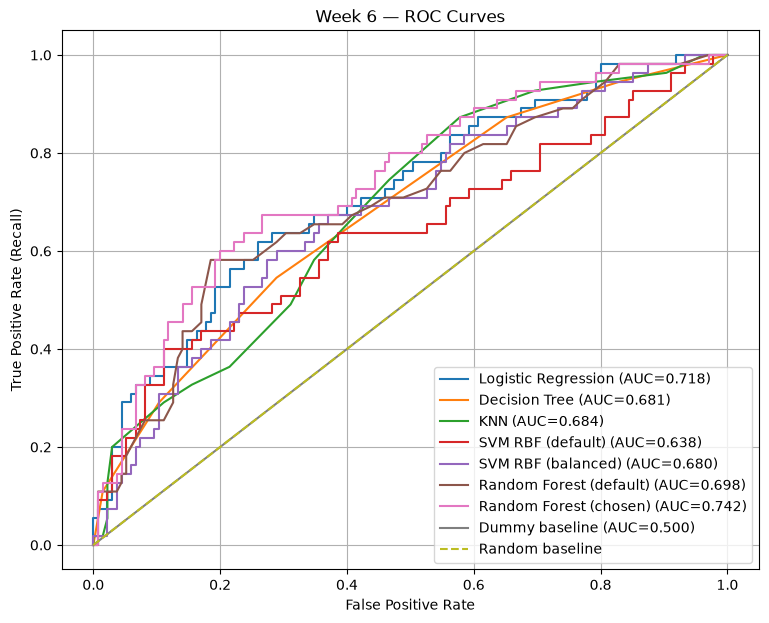

In [118]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

roc_specs = [
    ("Logistic Regression", logreg, x_test_scaled),
    ("Decision Tree", decision_tree, x_test),
    ("KNN", knn, x_test_scaled),
    ("SVM RBF (default)", svm_rbf, x_test_scaled),
    ("SVM RBF (balanced)", svm_rbf_bal, x_test_scaled),
    ("Random Forest (default)", rf, x_test),
    ("Random Forest (chosen)", rf_best, x_test),
    ("Dummy baseline", dummy_model, x_test)
]

plt.figure(figsize=(9, 7))
for name, model, Xt in roc_specs:
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(Xt)[:, 1]
    else:
        scores = model.decision_function(Xt)
    fpr, tpr, _ = roc_curve(y_test, scores)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")

plt.plot([0, 1], [0, 1], "--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Week 6 — ROC Curves")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


**T39 written answer:** The ROC curves compare true-positive rate against false-positive rate across thresholds. I compared the AUC ranking with the recall ranking. They may differ because AUC measures separation across many thresholds, while recall in the table measures performance at each model's selected threshold.

### T40 — Explain SVM and Random Forest in plain words

**Support Vector Machine (SVM):** An SVM tries to draw a boundary that separates two groups of patients. It pays special attention to the examples closest to that boundary because they help determine where it should go. The model predicts a patient's group based on which side of the boundary the patient falls on. Balanced class weights can make it pay more attention to diabetic patients.

**Random Forest:** A Random Forest combines the decisions of many decision trees. Each tree learns from a slightly different sample of the training data and may consider different features. The forest combines their predictions to produce one final prediction. This can make it more stable than relying on one tree, but its performance still needs to be measured.

### T41 — Note what surprised you

**T41 written answer:** One result that surprised me was **[model]**, which achieved **[metric and value]**. Another result worth investigating was **[model]**, whose **[metric]** differed from its ranking on recall. These observations are based on the results produced by my own test split.

### T42 — Update the observations log

**Week 6 observations:** I compared the models on the same test set using accuracy, precision, recall, F1, AUC and confusion-matrix counts. I compared the default models with class-weighted and threshold-tuned versions. My conclusion about complexity versus class weighting is **[fill in using the comparison table]**. The results come from one test split, so further validation is needed before treating small differences as reliable.

### T43 — Save the full comparison table

In [119]:
results.to_csv(r'C:\Users\USER\Desktop\5thsem_OJT\project1_diabeties\reports\figures\fizan_P1W6_result.csv', index=False)
print("Saved comparison table to fizan_p1W6_results.csv")


Saved comparison table to fizan_p1W6_results.csv


### T44 — Summary and Week 7 open questions

**Week 6 summary:** I compared Logistic Regression, Decision Tree, KNN, SVM and Random Forest using the same test split. I evaluated accuracy, precision, recall, F1 score, AUC and confusion-matrix counts. I also compared threshold tuning and balanced class weights to see whether they improved the project metric. My final model choice is based on the actual comparison table, not on complexity alone.

